In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost jupyter streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv(
    'kolkata_weather_jan_june_2026.csv'
)

print("Dataset berhasil dimuat.")
print("Jumlah baris dan kolom:", data.shape)

print("\n5 data pertama:")
display(data.head())

Dataset berhasil dimuat.
Jumlah baris dan kolom: (1827, 17)

5 data pertama:


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [4]:
print("Informasi Dataset:")
data.info()

print("\nNama Kolom:")
print(data.columns.tolist())

print("\nTipe Data:")
display(data.dtypes)

print("\nStatistik Deskriptif:")
display(data.describe())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   object 
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   object 
 12  sunset                       1827 non-null   object 
 13 

time                            object
weather_code                     int64
temperature_2m_mean            float64
temperature_2m_max             float64
temperature_2m_min             float64
precipitation_sum              float64
rain_sum                       float64
precipitation_hours            float64
wind_speed_10m_max             float64
wind_gusts_10m_max             float64
wind_direction_10m_dominant      int64
sunrise                         object
sunset                          object
sunshine_duration              float64
city                            object
latitude                       float64
longitude                      float64
dtype: object


Statistik Deskriptif:


,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,latitude,longitude
count,1827.000000,1827.00000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1.827000e+03,1.827000e+03
mean,34.143952,26.26486,31.099234,22.477066,5.429119,5.429119,4.952928,13.782157,30.756596,192.212917,33185.460542,2.257260e+01,8.836390e+01
std,28.997216,4.05022,3.924558,4.847343,9.550693,9.550693,6.275264,5.106847,9.081119,100.165783,9824.134424,3.553686e-15,2.842949e-14
min,0.000000,15.00000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,0.000000,2.257260e+01,8.836390e+01
25%,3.000000,23.40000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,30684.495000,2.257260e+01,8.836390e+01
50%,51.000000,27.40000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,36088.150000,2.257260e+01,8.836390e+01
75%,63.000000,29.10000,33.300000,26.200000,7.350000,7.350000,9.000000,16.600000,36.000000,258.000000,39550.540000,2.257260e+01,8.836390e+01
max,65.000000,35.20000,43.900000,30.600000,80.500000,80.500000,24.000000,44.000000,83.900000,360.000000,44569.280000,2.257260e+01,8.836390e+01


In [5]:
missing_values = data.isnull().sum()

print("Missing Value Setiap Kolom:")
display(missing_values.to_frame('Jumlah Missing Value'))

print(
    "Total Missing Value:",
    data.isnull().sum().sum()
)

Missing Value Setiap Kolom:


,Jumlah Missing Value
time,0
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0


Total Missing Value: 0


In [6]:
# Mengubah kolom time menjadi datetime
data['time'] = pd.to_datetime(data['time'])


# Mengambil bulan
data['month'] = data['time'].dt.month


# Membuat kategori musim
# Mengikuti pendekatan notebook teman:
# Winter  = Desember, Januari, Februari
# Summer  = Maret, April, Mei
# Monsoon = Juni sampai November

def get_season(month):

    if month in [12, 1, 2]:
        return 'Winter'

    elif month in [3, 4, 5]:
        return 'Summer'

    else:
        return 'Monsoon'


data['season'] = data['month'].apply(
    get_season
)

In [7]:

# ============================================================
# LANGKAH 7 - MEMBUAT KATEGORI ARAH ANGIN
# ============================================================

def get_wind_compass(degree):

    if degree >= 337.5 or degree < 22.5:
        return 'N'

    elif degree < 67.5:
        return 'NE'

    elif degree < 112.5:
        return 'E'

    elif degree < 157.5:
        return 'SE'

    elif degree < 202.5:
        return 'S'

    elif degree < 247.5:
        return 'SW'

    elif degree < 292.5:
        return 'W'

    else:
        return 'NW'


data['wind_compass'] = data[
    'wind_direction_10m_dominant'
].apply(get_wind_compass)

In [8]:
data['is_rainy'] = np.where(
    data['weather_code'] >= 51,
    1,
    0
)


print("Distribusi Target:")
display(
    data['is_rainy'].value_counts()
)

print("\nProporsi Target:")
display(
    data['is_rainy'].value_counts(
        normalize=True
    )
)



Distribusi Target:


is_rainy
1    1021
0     806
Name: count, dtype: int64


Proporsi Target:


is_rainy
1    0.55884
0    0.44116
Name: proportion, dtype: float64

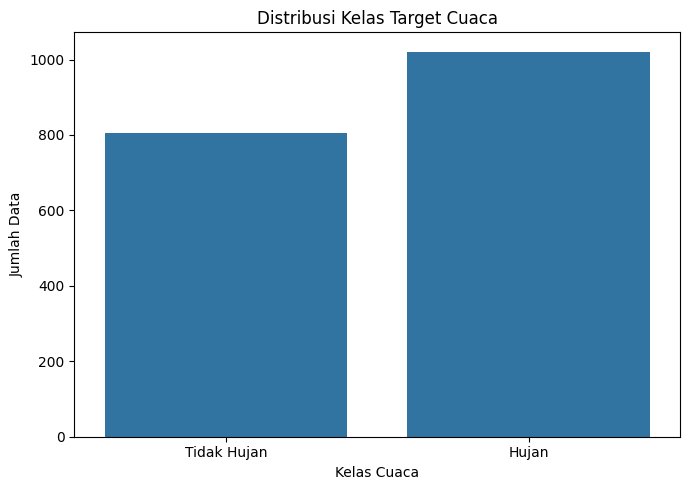

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x='is_rainy'
)

plt.title(
    'Distribusi Kelas Target Cuaca'
)

plt.xlabel('Kelas Cuaca')
plt.ylabel('Jumlah Data')

plt.xticks(
    [0, 1],
    ['Tidak Hujan', 'Hujan']
)

plt.tight_layout()
plt.show()


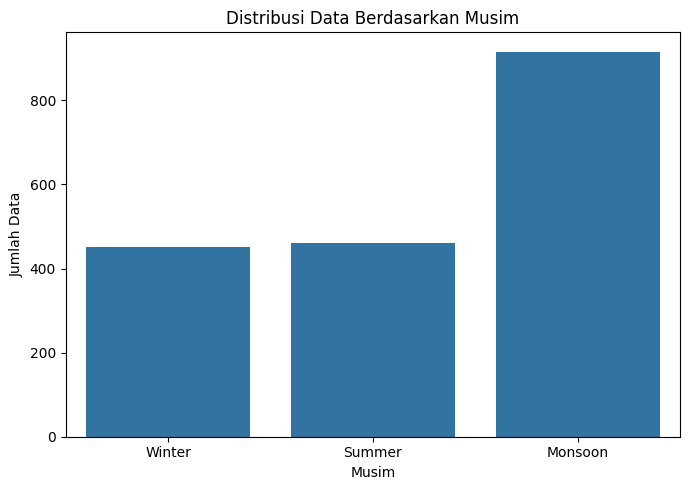

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x='season',
    order=[
        'Winter',
        'Summer',
        'Monsoon'
    ]
)

plt.title(
    'Distribusi Data Berdasarkan Musim'
)

plt.xlabel('Musim')
plt.ylabel('Jumlah Data')

plt.tight_layout()
plt.show()


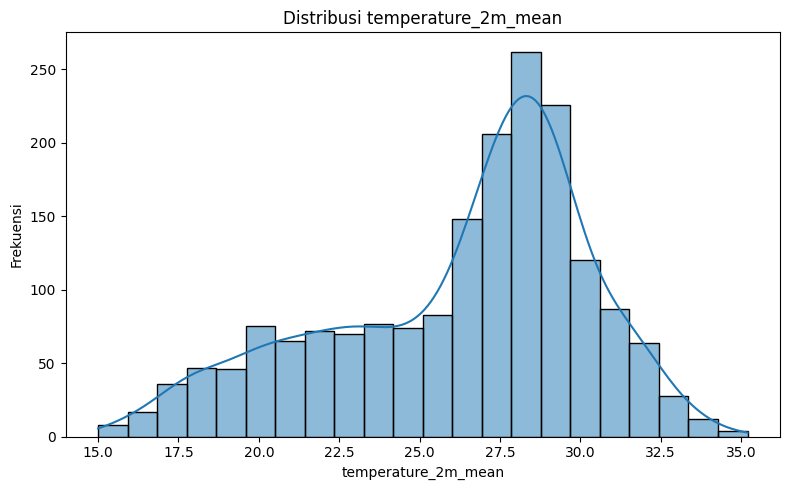

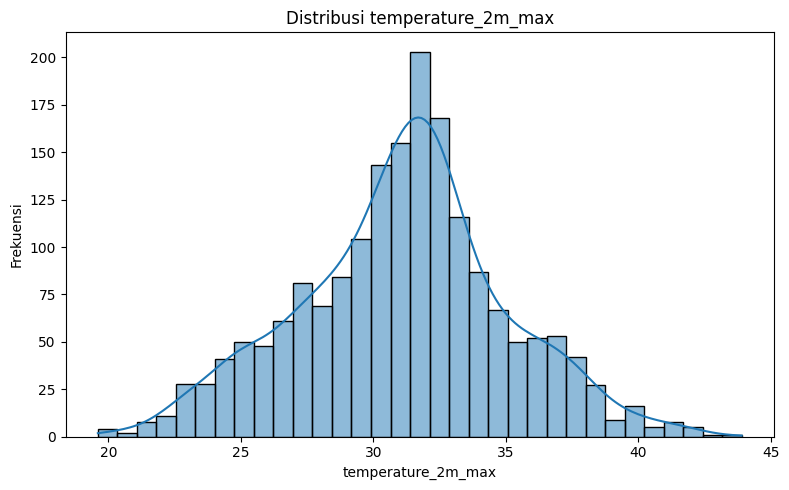

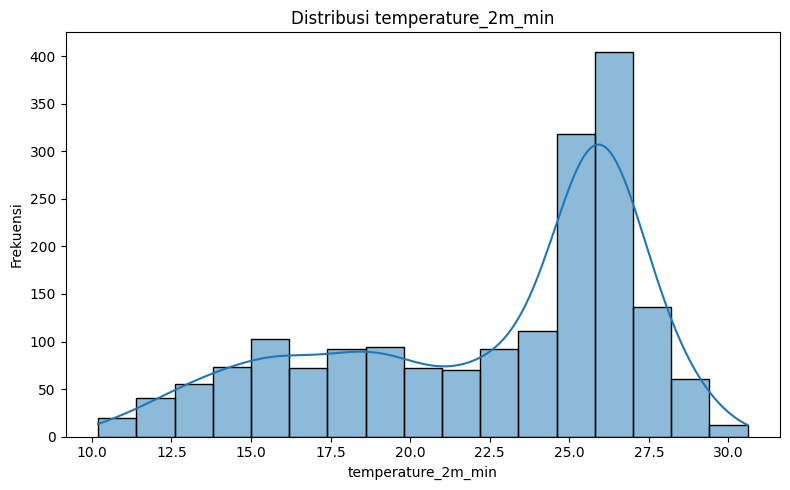

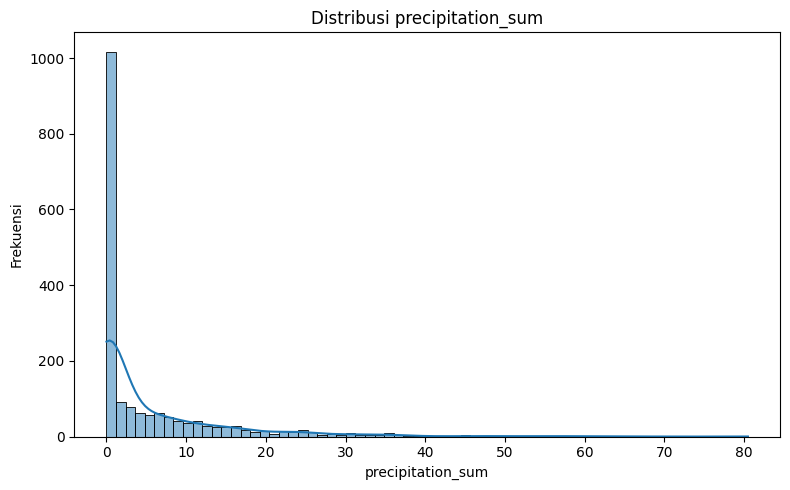

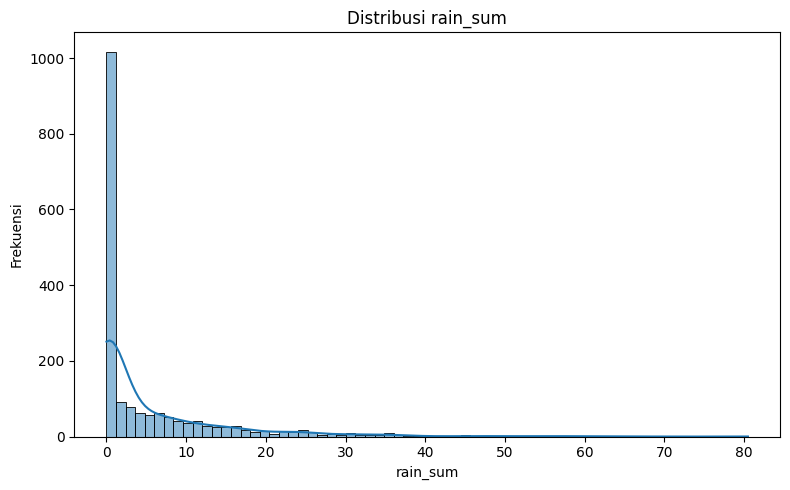

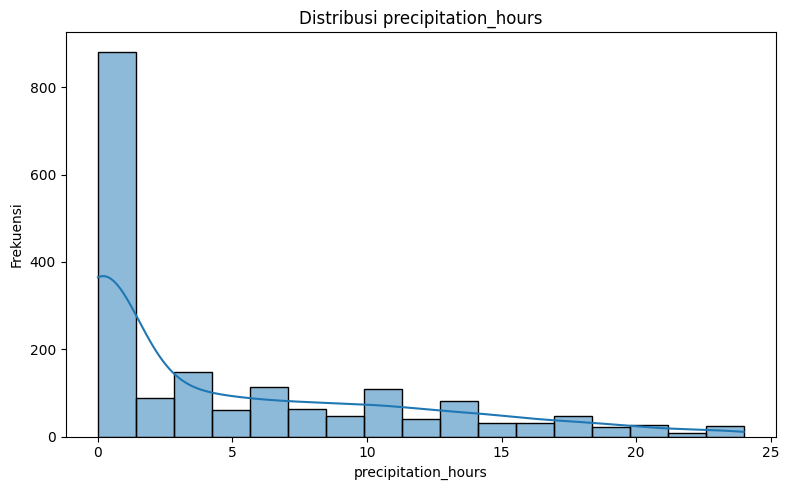

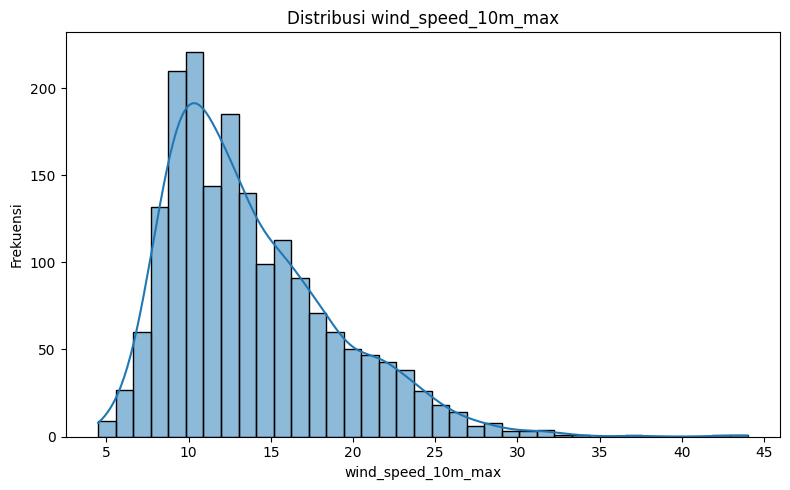

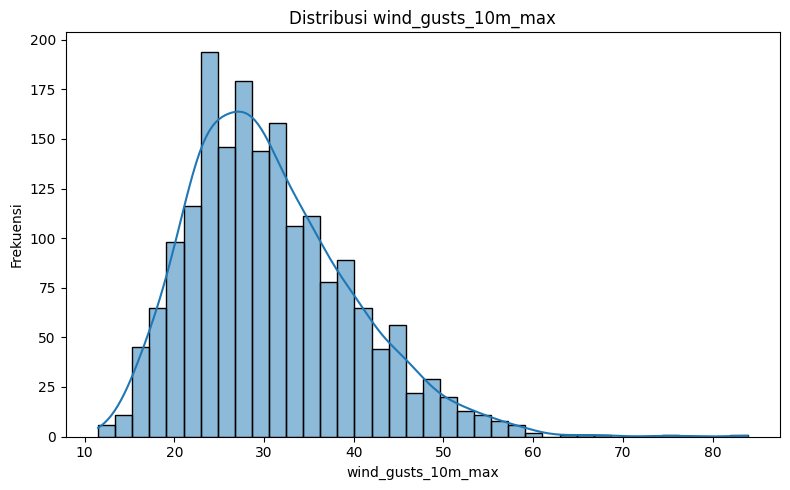

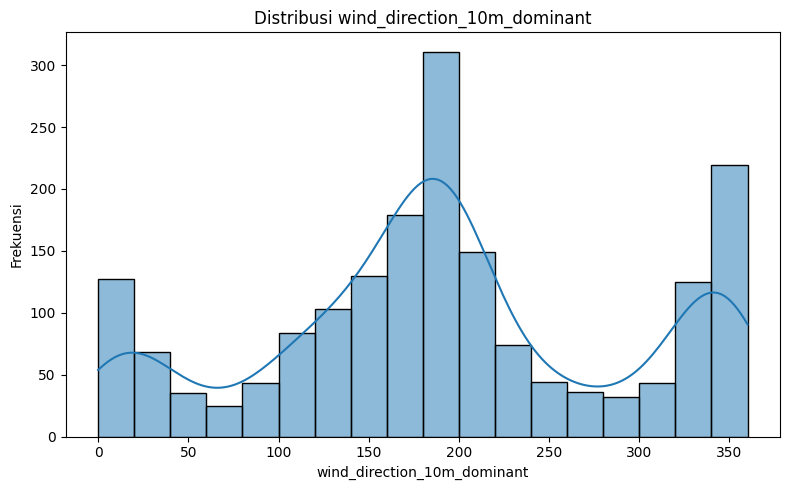

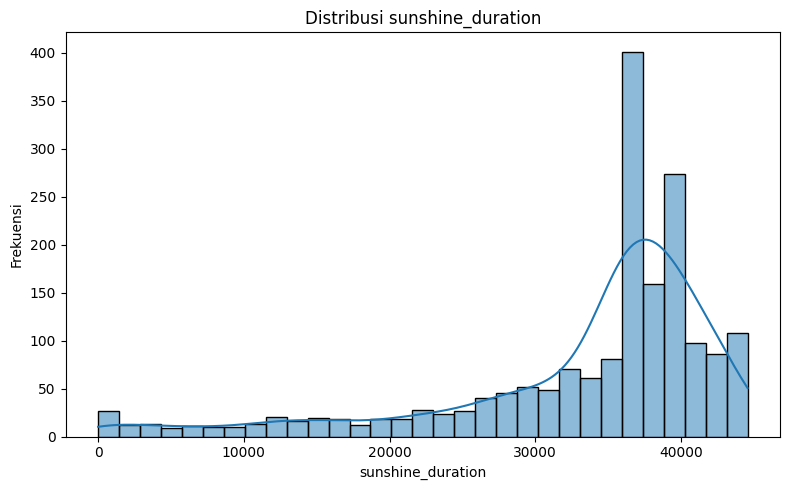

In [11]:
numeric_features_eda = [
    'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
    'precipitation_sum', 'rain_sum', 'precipitation_hours',
    'wind_speed_10m_max', 'wind_gusts_10m_max',
    'wind_direction_10m_dominant', 'sunshine_duration'
]


for feature in numeric_features_eda:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=data,
        x=feature,
        kde=True
    )

    plt.title(
        f'Distribusi {feature}'
    )

    plt.xlabel(feature)
    plt.ylabel('Frekuensi')

    plt.tight_layout()
    plt.show()

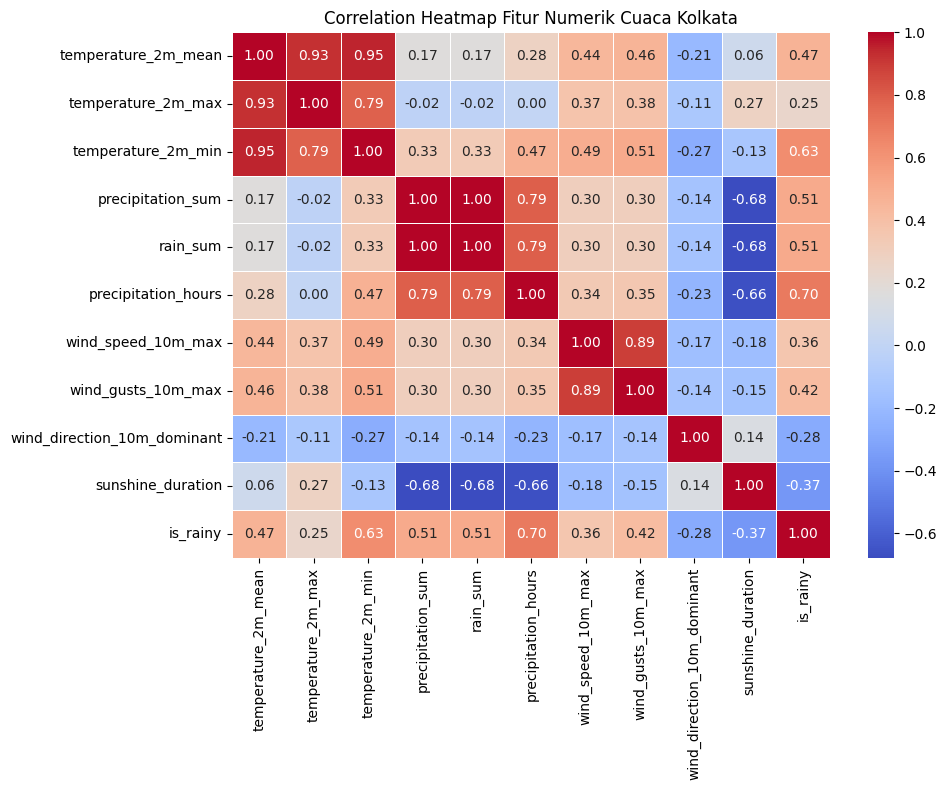

In [12]:
# ============================================================
# EDA - KORELASI ANTAR FITUR NUMERIK
# ============================================================

num_cols = [
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'precipitation_sum',
    'rain_sum',
    'precipitation_hours',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'wind_direction_10m_dominant',
    'sunshine_duration',
    'is_rainy'
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    data[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    'Correlation Heatmap Fitur Numerik Cuaca Kolkata'
)

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# MENENTUKAN FITUR (X) DAN TARGET (y)
# ============================================================

features = [
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'wind_direction_10m_dominant',
    'sunshine_duration',
    'season',
    'wind_compass'
]

X = data[features].copy()
y = data['is_rainy'].copy()

print("Fitur yang digunakan:")
print(features)

print("\nUkuran X:", X.shape)
print("Ukuran y:", y.shape)

display(X.head())
display(y.head())

Fitur yang digunakan:
['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration', 'season', 'wind_compass']

Ukuran X: (1827, 9)
Ukuran y: (1827,)


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,season,wind_compass
0,29.9,33.4,28.0,23.7,46.1,206,20837.76,Monsoon,SW
1,29.8,33.4,27.8,19.1,37.1,193,21439.24,Monsoon,S
2,29.2,32.2,27.8,18.7,33.8,209,12291.52,Monsoon,SW
3,29.2,32.9,27.3,15.5,32.0,202,29486.65,Monsoon,S
4,28.6,32.1,26.9,12.0,29.5,180,41145.46,Monsoon,S


0    1
1    1
2    1
3    1
4    1
Name: is_rainy, dtype: int64

In [14]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print(
    "Jumlah data training:",
    len(X_train)
)

print(
    "Jumlah data testing:",
    len(X_test)
)


print("\nDistribusi kelas training:")
display(
    y_train.value_counts(
        normalize=True
    )
)


print("\nDistribusi kelas testing:")
display(
    y_test.value_counts(
        normalize=True
    )
)


Jumlah data training: 1461
Jumlah data testing: 366

Distribusi kelas training:


is_rainy
1    0.558522
0    0.441478
Name: proportion, dtype: float64


Distribusi kelas testing:


is_rainy
1    0.560109
0    0.439891
Name: proportion, dtype: float64

In [15]:
le_season = LabelEncoder()
le_wind = LabelEncoder()


# Encoding season
X_train['season'] = le_season.fit_transform(
    X_train['season']
)

X_test['season'] = le_season.transform(
    X_test['season']
)


# Encoding wind_compass
X_train['wind_compass'] = le_wind.fit_transform(
    X_train['wind_compass']
)

X_test['wind_compass'] = le_wind.transform(
    X_test['wind_compass']
)


print("Encoding season:")
for label, code in zip(
    le_season.classes_,
    le_season.transform(
        le_season.classes_
    )
):
    print(f"{label} = {code}")


print("\nEncoding wind_compass:")
for label, code in zip(
    le_wind.classes_,
    le_wind.transform(
        le_wind.classes_
    )
):
    print(f"{label} = {code}")


Encoding season:
Monsoon = 0
Summer = 1
Winter = 2

Encoding wind_compass:
E = 0
N = 1
NE = 2
NW = 3
S = 4
SE = 5
SW = 6
W = 7


In [16]:
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(
    X_train
)


X_test_scaled = scaler.transform(
    X_test
)


print(
    "Pra-pemrosesan selesai tanpa data leakage!"
)



Pra-pemrosesan selesai tanpa data leakage!


In [17]:
# ============================================================
# MENYIMPAN DATA YANG SUDAH DINORMALISASI KE CSV
# ============================================================

# Mengubah hasil normalisasi menjadi DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Menambahkan target
X_train_scaled_df['is_rainy'] = y_train
X_test_scaled_df['is_rainy'] = y_test

# Menggabungkan data training dan testing
normalized_data = pd.concat(
    [X_train_scaled_df, X_test_scaled_df]
).sort_index()

# Menyimpan ke CSV
normalized_data.to_csv(
    'data_weather_normalized.csv',
    index=False
)

print("Data yang sudah dinormalisasi berhasil disimpan.")
print("Nama file: data_weather_normalized.csv")

# Melihat 5 data pertama
display(normalized_data.head())

Data yang sudah dinormalisasi berhasil disimpan.
Nama file: data_weather_normalized.csv


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,season,wind_compass,is_rainy
0,0.892228,0.574137,1.137577,1.964611,1.680790,0.137518,-1.261029,-0.906462,1.311754,1
1,0.867438,0.574137,1.096176,1.055833,0.689656,0.006675,-1.199625,-0.906462,0.286902,1
2,0.718696,0.268242,1.096176,0.976809,0.326240,0.167712,-2.133504,-0.906462,1.311754,1
3,0.718696,0.446681,0.992672,0.344615,0.128013,0.097259,-0.378074,-0.906462,0.286902,1
4,0.569955,0.242751,0.909869,-0.346846,-0.147302,-0.124167,0.812159,-0.906462,0.286902,1


In [18]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)


xgb_model.fit(
    X_train_scaled,
    y_train
)


print(
    "Model XGBoost berhasil dilatih."
)

Model XGBoost berhasil dilatih.


In [19]:
y_pred = xgb_model.predict(
    X_test_scaled
)


y_pred_proba = xgb_model.predict_proba(
    X_test_scaled
)[:, 1]


print("Prediksi data testing selesai.")


Prediksi data testing selesai.


In [20]:
accuracy = accuracy_score(
    y_test,
    y_pred
)


precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)


recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)


f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


auc_score = roc_auc_score(
    y_test,
    y_pred_proba
)


metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC'
    ],

    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})


print("HASIL EVALUASI MODEL")

display(
    metrics_df
)

HASIL EVALUASI MODEL


,Metric,Score
0,Accuracy,0.879781
1,Precision,0.900498
2,Recall,0.882927
3,F1-Score,0.891626
4,ROC-AUC,0.946432


In [21]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Tidak Hujan',
            'Hujan'
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 Tidak Hujan       0.85      0.88      0.87       161
       Hujan       0.90      0.88      0.89       205

    accuracy                           0.88       366
   macro avg       0.88      0.88      0.88       366
weighted avg       0.88      0.88      0.88       366



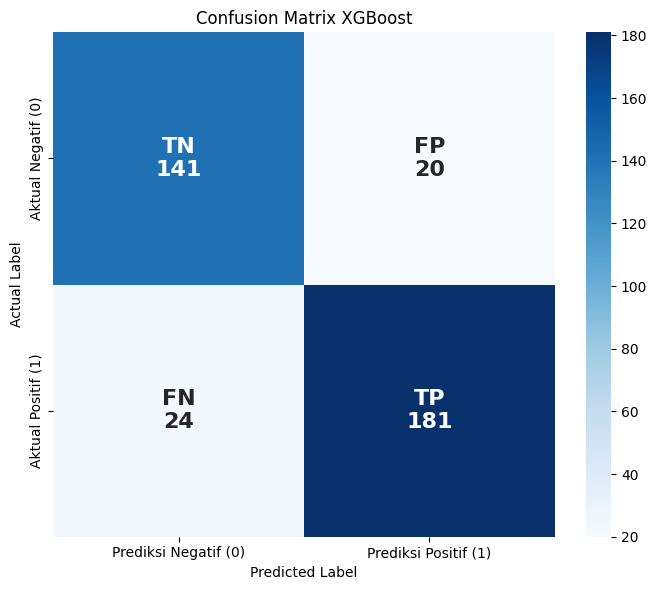

In [22]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Teks di setiap kotak: label + jumlah
labels = np.array([
    [f"TN\n{tn}", f"FP\n{fp}"],
    [f"FN\n{fn}", f"TP\n{tp}"]
])

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=labels,
    fmt='',                      # wajib kosong karena annot berupa teks
    cmap='Blues',
    annot_kws={'size': 16, 'weight': 'bold'},
    xticklabels=['Prediksi Negatif (0)', 'Prediksi Positif (1)'],
    yticklabels=['Aktual Negatif (0)', 'Aktual Positif (1)']
)

plt.title('Confusion Matrix XGBoost')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

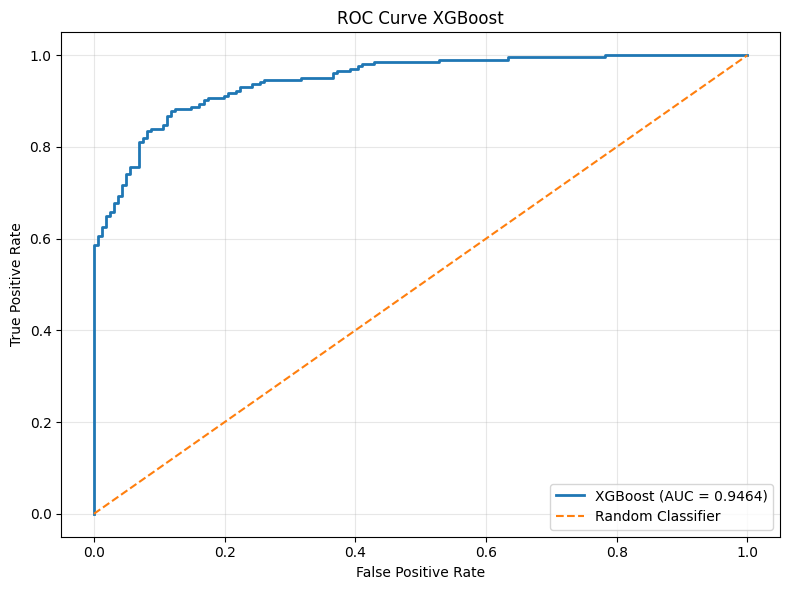

In [23]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba
)


plt.figure(figsize=(8, 6))


plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'XGBoost (AUC = {auc_score:.4f})'
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)


plt.xlabel(
    'False Positive Rate'
)

plt.ylabel(
    'True Positive Rate'
)

plt.title(
    'ROC Curve XGBoost'
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:
importances = pd.DataFrame({
    'Feature': features,
    'Importance': xgb_model.feature_importances_
})


importances = importances.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)


print(
    "Ranking Feature Importance:"
)

display(
    importances
)


Ranking Feature Importance:


,Feature,Importance
0,temperature_2m_min,0.389451
1,temperature_2m_max,0.158980
2,sunshine_duration,0.122561
3,wind_direction_10m_dominant,0.098378
4,temperature_2m_mean,0.065180
5,wind_gusts_10m_max,0.055116
6,wind_speed_10m_max,0.039923
7,wind_compass,0.036726
8,season,0.033686


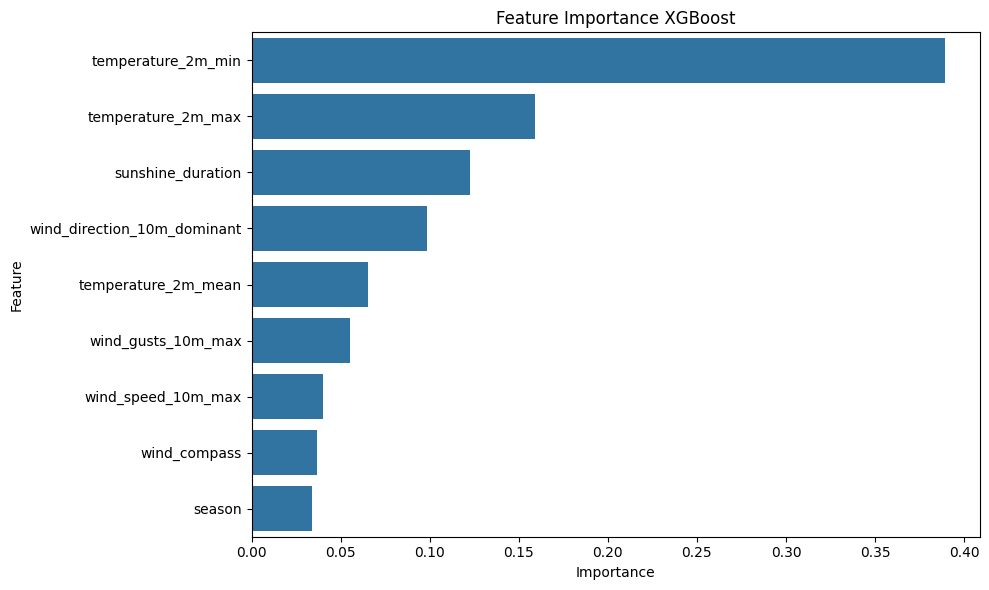

In [25]:
plt.figure(figsize=(10, 6))


sns.barplot(
    data=importances,
    x='Importance',
    y='Feature'
)


plt.title(
    'Feature Importance XGBoost'
)

plt.xlabel(
    'Importance'
)

plt.ylabel(
    'Feature'
)

plt.tight_layout()
plt.show()



In [26]:
tn, fp, fn, tp = cm.ravel()


print("ANALISIS CONFUSION MATRIX")
print("=" * 50)

print(
    f"True Negative  : {tn}"
)

print(
    f"False Positive : {fp}"
)

print(
    f"False Negative : {fn}"
)

print(
    f"True Positive  : {tp}"
)

ANALISIS CONFUSION MATRIX
True Negative  : 141
False Positive : 20
False Negative : 24
True Positive  : 181


In [27]:
print("ANALISIS PERFORMA MODEL")
print("=" * 50)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print(
    f"ROC-AUC   : {auc_score:.4f}"
)

ANALISIS PERFORMA MODEL
Accuracy  : 0.8798
Precision : 0.9005
Recall    : 0.8829
F1-Score  : 0.8916
ROC-AUC   : 0.9464


In [28]:
# ============================================================
# LANGKAH 28 - MEMBUAT RINGKASAN DATASET
# UNTUK KEPERLUAN STREAMLIT
# ============================================================

dataset_summary = pd.DataFrame({
    'Informasi': [
        'Jumlah Data',
        'Jumlah Fitur',
        'Data Training',
        'Data Testing',
        'Jumlah Tidak Hujan',
        'Jumlah Hujan',
        'Proporsi Tidak Hujan',
        'Proporsi Hujan'
    ],

    'Nilai': [
        len(data),
        len(features),
        len(X_train),
        len(X_test),
        int((data['is_rainy'] == 0).sum()),
        int((data['is_rainy'] == 1).sum()),
        float(
            (data['is_rainy'] == 0).mean()
        ),
        float(
            (data['is_rainy'] == 1).mean()
        )
    ]
})


display(
    dataset_summary
)


# ============================================================
# LANGKAH 29 - MENYIMPAN MODEL
# ============================================================

with open(
    'model.pkl',
    'wb'
) as f:

    pickle.dump(
        xgb_model,
        f
    )


# ============================================================
# LANGKAH 30 - MENYIMPAN SCALER
# ============================================================

with open(
    'scaler.pkl',
    'wb'
) as f:

    pickle.dump(
        scaler,
        f
    )


# ============================================================
# LANGKAH 31 - MENYIMPAN ENCODER SEASON
# ============================================================

with open(
    'le_season.pkl',
    'wb'
) as f:

    pickle.dump(
        le_season,
        f
    )


# ============================================================
# LANGKAH 32 - MENYIMPAN ENCODER WIND COMPASS
# ============================================================

with open(
    'le_wind.pkl',
    'wb'
) as f:

    pickle.dump(
        le_wind,
        f
    )


# ============================================================
# LANGKAH 33 - MENYIMPAN DATA EVALUASI
# UNTUK STREAMLIT
# ============================================================

eval_artifacts = {

    'metrics_df': metrics_df,

    'cm': cm,

    'fpr': fpr,

    'tpr': tpr,

    'auc': auc_score,

    'importances': importances,

    'data': data,

    'features': features
}


with open(
    'eval_data.pkl',
    'wb'
) as f:

    pickle.dump(
        eval_artifacts,
        f
    )


print(
    "Seluruh file .pkl berhasil disimpan."
)


# ============================================================
# LANGKAH 34 - MEMERIKSA FILE ARTIFACT
# ============================================================

artifact_files = [
    'model.pkl',
    'scaler.pkl',
    'le_season.pkl',
    'le_wind.pkl',
    'eval_data.pkl'
]


print(
    "Pemeriksaan file artifact:"
)


for file in artifact_files:

    if os.path.exists(file):

        print(
            f"✓ {file} berhasil dibuat"
        )

    else:

        print(
            f"✗ {file} tidak ditemukan"
        )


# ============================================================
# LANGKAH 35 - MENYIMPAN HASIL PREDIKSI
# ============================================================

prediction_result = X_test.copy()


prediction_result['Actual'] = y_test.values

prediction_result['Predicted'] = y_pred

prediction_result['Probability_Rain'] = y_pred_proba


display(
    prediction_result.head(10)
)


# ============================================================
# LANGKAH 36 - RINGKASAN AKHIR PRAKTIKUM
# ============================================================

print("=" * 60)
print("RINGKASAN PRAKTIKUM")
print("=" * 60)

print(
    f"Jumlah Dataset       : {len(data)}"
)

print(
    f"Jumlah Fitur         : {len(features)}"
)

print(
    f"Training Data        : {len(X_train)} ({len(X_train)/len(data)*100:.0f}%)"
)

print(
    f"Testing Data         : {len(X_test)} ({len(X_test)/len(data)*100:.0f}%)"
)

print(
    f"Accuracy             : {accuracy:.4f}"
)

print(
    f"Precision            : {precision:.4f}"
)

print(
    f"Recall               : {recall:.4f}"
)

print(
    f"F1-Score             : {f1:.4f}"
)

print(
    f"ROC-AUC              : {auc_score:.4f}"
)

print("=" * 60)
print(
    "Notebook selesai dan artifact siap digunakan untuk Streamlit."
)

,Informasi,Nilai
0,Jumlah Data,1827.00000
1,Jumlah Fitur,9.00000
2,Data Training,1461.00000
3,Data Testing,366.00000
4,Jumlah Tidak Hujan,806.00000
5,Jumlah Hujan,1021.00000
6,Proporsi Tidak Hujan,0.44116
7,Proporsi Hujan,0.55884


Seluruh file .pkl berhasil disimpan.
Pemeriksaan file artifact:
✓ model.pkl berhasil dibuat
✓ scaler.pkl berhasil dibuat
✓ le_season.pkl berhasil dibuat
✓ le_wind.pkl berhasil dibuat
✓ eval_data.pkl berhasil dibuat


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,season,wind_compass,Actual,Predicted,Probability_Rain
1002,28.0,34.5,23.0,16.5,36.0,185,36141.06,1,4,1,0,0.428647
1451,28.9,32.6,26.3,17.3,42.8,202,34198.61,0,4,1,1,0.998472
510,22.3,28.1,16.6,11.6,24.1,349,36109.77,0,1,0,0,0.003910
39,27.9,30.8,25.9,16.4,31.7,195,20083.45,0,4,1,1,0.998691
60,27.7,30.7,25.9,15.6,38.5,129,32297.13,0,5,1,1,0.999392
293,30.1,34.9,26.2,23.8,45.4,181,37903.22,1,4,0,1,0.938978
795,28.3,32.8,26.3,13.8,29.2,83,26524.36,0,0,1,1,0.997749
1508,28.8,32.2,26.4,10.5,30.2,117,36000.00,0,5,1,1,0.999379
1477,28.5,32.0,26.4,13.5,35.6,162,22333.54,0,4,1,1,0.999312
1753,30.2,34.9,27.0,12.7,31.0,191,39600.00,1,4,0,1,0.687424


RINGKASAN PRAKTIKUM
Jumlah Dataset       : 1827
Jumlah Fitur         : 9
Training Data        : 1461 (80%)
Testing Data         : 366 (20%)
Accuracy             : 0.8798
Precision            : 0.9005
Recall               : 0.8829
F1-Score             : 0.8916
ROC-AUC              : 0.9464
Notebook selesai dan artifact siap digunakan untuk Streamlit.
